In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# 17장 오토인코더, GAN 그리고 확산 모델

## 17.2 과소완전 선형 오토인코더로 PCA 수행하기

In [2]:
tf.random.set_seed(42)

encoder = tf.keras.models.Sequential([tf.keras.layers.Dense(2)])
decoder = tf.keras.models.Sequential([tf.keras.layers.Dense(3)])
autoencoder = tf.keras.models.Sequential([encoder, decoder])

optimizer = tf.keras.optimizers.SGD(learning_rate=0.5)
autoencoder.compile(loss='mse', optimizer=optimizer)

In [3]:
from scipy.spatial.transform import Rotation

m = 60
X = np.zeros((m, 3))
np.random.seed(42)
angles = (np.random.rand(m) ** 3 + 0.5) * 2 * np.pi
X[:, 0], X[:, 1] = np.cos(angles), np.sin(angles) * 0.5
X += 0.28 * np.random.randn(m, 3)
X = Rotation.from_rotvec([np.pi / 29, -np.pi / 20, np.pi / 4]).apply(X)
X_train = X + [0.2, 0, 0.2]

In [4]:
history = autoencoder.fit(X_train, X_train, epochs=500, verbose=False)
codings = encoder.predict(X_train)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


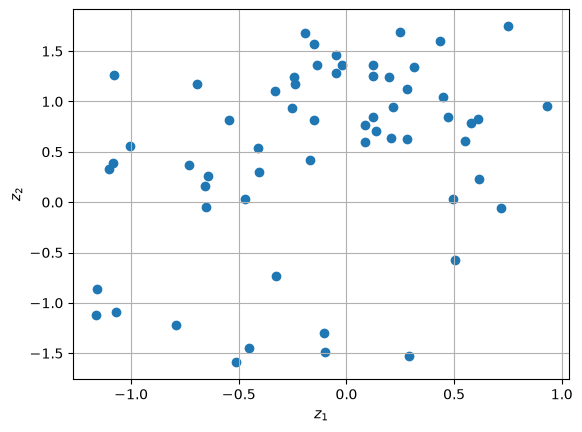

In [5]:
plt.scatter(codings[:, 0], codings[:, 1])
plt.xlabel('$z_1$')
plt.ylabel('$z_2$')
plt.grid()
plt.show()

## 17.3 적층 오토인코더

### 17.3.1 케라스로 적층 오토인코더 구현하기

In [6]:
fashion_mnist = tf.keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist
X_train_full = X_train_full.astype(np.float32) / 255
X_test = X_test.astype(np.float32) / 255
X_train, X_valid = X_train_full[:-5000], X_train_full[-5000:]
y_train, y_valid = y_train_full[:-5000], y_train_full[-5000:]

In [7]:
tf.random.set_seed(42)

stacked_encoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(30, activation='relu')
])

stacked_decoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(30,)),
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(28 * 28),
    tf.keras.layers.Reshape([28, 28])
])

stacked_ae = tf.keras.models.Sequential([stacked_encoder, stacked_decoder])

stacked_ae.compile(loss='mse', optimizer='nadam')
history = stacked_ae.fit(X_train, X_train, epochs=20, validation_data=(X_train, X_train))

Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.0235 - val_loss: 0.0179
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 0.0169 - val_loss: 0.0163
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0158 - val_loss: 0.0156
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0153 - val_loss: 0.0151
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0150 - val_loss: 0.0148
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0147 - val_loss: 0.0146
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0145 - val_loss: 0.0144
Epoch 8/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0144 - val_loss: 0.0143
Epoch 9/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0142 - val_loss: 0.0142
Epoch 10/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0141 - val_loss: 0.0141
Epoch 11/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0140 - val_loss: 0.0140
Epoch 12/20
1719/1719 ━━━━━━━━

### 17.3.2 재구성 시각화

In [8]:
def plot_reconstructions(model, images=X_valid, n_images=5):
    reconstructions = np.clip(model.predict(images[:n_images]), 0, 1)
    fig = plt.figure(figsize=(n_images * 1.5, 3))

    for image_index in range(n_images):
        plt.subplot(2, n_images, 1 + image_index)
        plt.imshow(images[image_index], cmap='binary')
        plt.axis('off')
        plt.subplot(2, n_images, 1 + image_index + n_images)
        plt.imshow(reconstructions[image_index], cmap='binary')
        plt.axis('off')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step


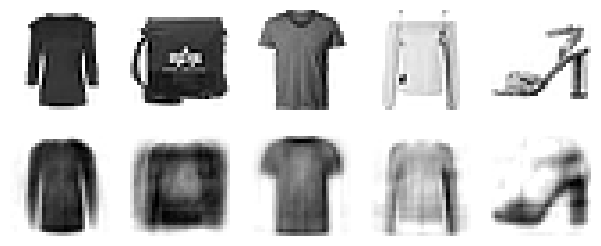

In [9]:
plot_reconstructions(stacked_ae)
plt.show()

### 17.3.3 패션 MNIST 데이터셋 시각화

In [10]:
from sklearn.manifold import TSNE

X_valid_compressed = stacked_encoder.predict(X_valid)
tsne = TSNE(init='pca', learning_rate='auto', random_state=42)
X_valid_2D = tsne.fit_transform(X_valid_compressed)

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 555us/step


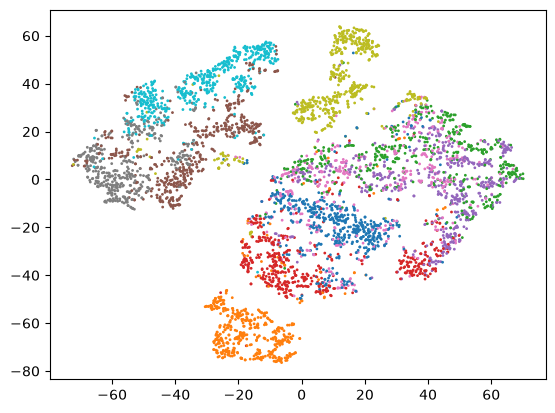

In [11]:
plt.scatter(X_valid_2D[:, 0], X_valid_2D[:, 1], c=y_valid, s=1, cmap='tab10')
plt.show()

### 17.3.5 가중치 묶기

In [12]:
class DenseTranspose(tf.keras.layers.Layer):
    def __init__(self, dense, activation=None, **kwargs):
        super().__init__(**kwargs)
        self.dense = dense
        self.activation = tf.keras.activations.get(activation)

    def build(self, batch_input_shape):
        kernel = self.dense.kernel
        self.biases = self.add_weight(name='bias',
                                      shape=(kernel.shape[0],),
                                      initializer='zeros')
        super().build(batch_input_shape)

    def call(self, inputs, training=False):
        Z = tf.matmul(inputs, self.dense.weights[0], transpose_b=True)
        return self.activation(Z + self.biases)

In [13]:
tf.random.set_seed(42)

dense_1 = tf.keras.layers.Dense(100, activation='relu')
dense_2 = tf.keras.layers.Dense(30, activation='relu')

tied_encoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    dense_1,
    dense_2,
])
tied_decoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(30,)),
    DenseTranspose(dense_2, activation='relu'),
    DenseTranspose(dense_1),
    tf.keras.layers.Reshape([28, 28])
])
tied_ae = tf.keras.models.Sequential([tied_encoder, tied_decoder])

tied_ae.compile(loss='mse', optimizer='nadam')
history = tied_ae.fit(X_train, X_train, epochs=20, validation_data=(X_valid, X_valid))

Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0229 - val_loss: 0.0172
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - loss: 0.0162 - val_loss: 0.0157
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - loss: 0.0150 - val_loss: 0.0148
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - loss: 0.0144 - val_loss: 0.0144
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - loss: 0.0141 - val_loss: 0.0142
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - loss: 0.0139 - val_loss: 0.0140
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0137 - val_loss: 0.0139
Epoch 8/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0136 - val_loss: 0.0138
Epoch 9/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0135 - val_loss: 0.0137
Epoch 10/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0134 - val_loss: 0.0136
Epoch 11/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0134 - val_loss: 0.0135
Epoch 12/20
1719/1719 ━━━━━━━━

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


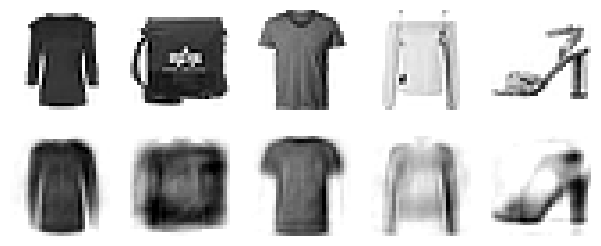

In [14]:
plot_reconstructions(tied_ae)
plt.show()

### 17.3.6 오토인코더 한 개씩 훈련하기

In [15]:
def train_autoencoder(n_neurons, X_train, X_valid, epochs=10,
                      output_activation=None):
    n_inputs = X_train.shape[-1]
    encoder = tf.keras.layers.Dense(n_neurons, activation='relu')
    decoder = tf.keras.layers.Dense(n_inputs, activation=output_activation)
    autoencoder = tf.keras.models.Sequential([encoder, decoder])
    autoencoder.compile(loss='mse', optimizer='nadam')
    autoencoder.fit(X_train, X_train, epochs=epochs,
                    validation_data=(X_valid, X_valid))
    return encoder, decoder, encoder(X_train), encoder(X_valid)

In [16]:
tf.random.set_seed(42)

X_train_flat = tf.keras.layers.Flatten()(X_train)
X_valid_flat = tf.keras.layers.Flatten()(X_valid)

enc1, dec1, X_train_enc1, X_valid_enc1 = train_autoencoder(100, X_train_flat, X_valid_flat)
enc2, dec2, _, _ = train_autoencoder(30, X_train_enc1, X_valid_enc1, output_activation='relu')

Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0182 - val_loss: 0.0112
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0104 - val_loss: 0.0099
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0097 - val_loss: 0.0095
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0094 - val_loss: 0.0093
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0093 - val_loss: 0.0092
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0092 - val_loss: 0.0092
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0092 - val_loss: 0.0091
Epoch 8/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0092 - val_loss: 0.0090
Epoch 9/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0091 - val_loss: 0.0091
Epoch 10/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0091 - val_loss: 0.0090
Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 1s 566us/step - loss: 0.0986 - val_loss: 0.0678
Epoch 2/10
1719/1719 ━━━━━━━━

In [17]:
stack_ae_1_by_1 = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    enc1, enc2, dec2, dec1,
    tf.keras.layers.Reshape([28, 28])
])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


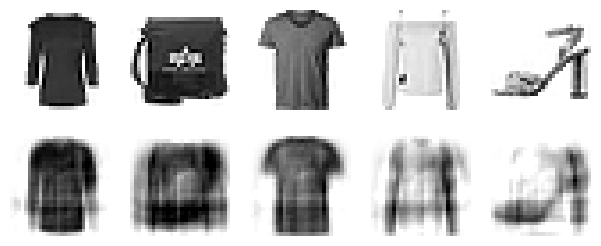

In [18]:
plot_reconstructions(stack_ae_1_by_1)
plt.show()

## 17.4 합성곱 오토인코더

In [19]:
tf.random.set_seed(42)

conv_encoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Reshape((28, 28, 1)),
    tf.keras.layers.Conv2D(16, 3, padding='same', activation='relu'),
    tf.keras.layers.MaxPool2D(pool_size=2),  # (14, 14, 16)
    tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu'),
    tf.keras.layers.MaxPool2D(pool_size=2),  # (7, 7, 32)
    tf.keras.layers.Conv2D(64, 3, padding='same', activation='relu'),
    tf.keras.layers.MaxPool2D(pool_size=2),  # (3, 3, 64)
    tf.keras.layers.Conv2D(30, 3, padding='same', activation='relu'),
    tf.keras.layers.GlobalAvgPool2D()        # (30,)
])

conv_decoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(30,)),
    tf.keras.layers.Dense(3 * 3 * 16),
    tf.keras.layers.Reshape((3, 3, 16)),
    tf.keras.layers.Conv2DTranspose(32, 3, strides=2, activation='relu'),
    tf.keras.layers.Conv2DTranspose(16, 3, strides=2, padding='same', activation='relu'),
    tf.keras.layers.Conv2DTranspose(1, 3, strides=2, padding='same'),
    tf.keras.layers.Reshape((28, 28))
])

conv_ae = tf.keras.models.Sequential([conv_encoder, conv_decoder])
conv_ae.compile(loss='mse', optimizer='nadam')
history = conv_ae.fit(X_train, X_train, epochs=10, validation_data=(X_valid, X_valid))

Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 22s 12ms/step - loss: 0.0303 - val_loss: 0.0218
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - loss: 0.0191 - val_loss: 0.0183
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - loss: 0.0169 - val_loss: 0.0169
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - loss: 0.0157 - val_loss: 0.0161
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - loss: 0.0148 - val_loss: 0.0156
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - loss: 0.0141 - val_loss: 0.0154
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 21s 12ms/step - loss: 0.0136 - val_loss: 0.0146
Epoch 8/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - loss: 0.0132 - val_loss: 0.0139
Epoch 9/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 23s 13ms/step - loss: 0.0129 - val_loss: 0.0135
Epoch 10/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 23s 13ms/step - loss: 0.0126 - val_loss: 0.0127


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step


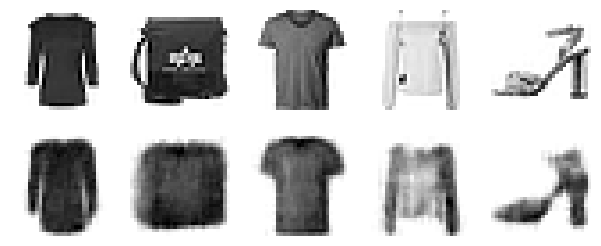

In [20]:
plot_reconstructions(conv_ae)
plt.show()

In [21]:
tf.random.set_seed(42)

recurrent_encoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.LSTM(100, return_sequences=True),
    tf.keras.layers.LSTM(30)
])

recurrent_decoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(30,)),
    tf.keras.layers.RepeatVector(28),
    tf.keras.layers.LSTM(100, return_sequences=True),
    tf.keras.layers.Dense(28)
])

recurrent_ae = tf.keras.models.Sequential([recurrent_encoder, recurrent_decoder])
recurrent_ae.compile(loss='mse', optimizer='nadam')
history = recurrent_ae.fit(X_train, X_train, epochs=10, validation_data=(X_valid, X_valid))

Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 52s 28ms/step - loss: 0.0260 - val_loss: 0.0194
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 54s 31ms/step - loss: 0.0175 - val_loss: 0.0162
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 50s 29ms/step - loss: 0.0153 - val_loss: 0.0143
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 44s 26ms/step - loss: 0.0140 - val_loss: 0.0135
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 57s 33ms/step - loss: 0.0131 - val_loss: 0.0129
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 59s 34ms/step - loss: 0.0124 - val_loss: 0.0124
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 55s 32ms/step - loss: 0.0118 - val_loss: 0.0119
Epoch 8/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 58s 33ms/step - loss: 0.0114 - val_loss: 0.0113
Epoch 9/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 57s 33ms/step - loss: 0.0110 - val_loss: 0.0109
Epoch 10/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 56s 32ms/step - loss: 0.0107 - val_loss: 0.0106


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step


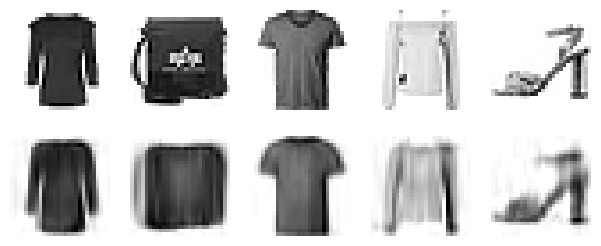

In [22]:
plot_reconstructions(recurrent_ae)
plt.show()

## 17.5 잡음 제거 오토인코더

In [23]:
tf.random.set_seed(42)

dropout_encoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(30, activation='relu')
])

dropout_decoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(30,)),
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(28 * 28, activation='relu'),
    tf.keras.layers.Reshape((28, 28))
])

dropout_ae = tf.keras.models.Sequential([dropout_encoder, dropout_decoder])
dropout_ae.compile(loss='mse', optimizer='nadam')
history = dropout_ae.fit(X_train, X_train, epochs=10, validation_data=(X_valid, X_valid))

Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - loss: 0.0402 - val_loss: 0.0315
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0308 - val_loss: 0.0279
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0283 - val_loss: 0.0260
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0263 - val_loss: 0.0241
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 0.0252 - val_loss: 0.0236
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 0.0249 - val_loss: 0.0233
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0245 - val_loss: 0.0230
Epoch 8/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0243 - val_loss: 0.0228
Epoch 9/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0240 - val_loss: 0.0222
Epoch 10/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0235 - val_loss: 0.0218


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


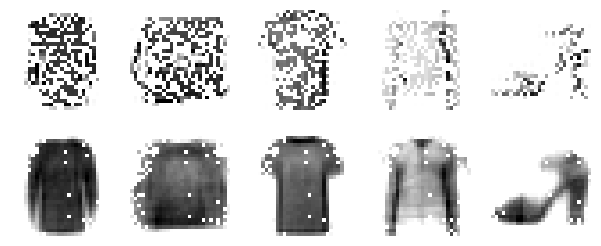

In [24]:
dropout = tf.keras.layers.Dropout(0.5)
plot_reconstructions(dropout_ae, dropout(X_valid, training=True))
plt.show()

## 17.6 희소 오토인코더

In [25]:
tf.random.set_seed(42)

sparse_l1_encoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(300, activation='sigmoid'),
    tf.keras.layers.ActivityRegularization(l1=1e-4)
])

sparse_l1_decoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(300,)),
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(28 * 28),
    tf.keras.layers.Reshape((28, 28))
])

sparse_l1_ae = tf.keras.models.Sequential([sparse_l1_encoder, sparse_l1_decoder])
sparse_l1_ae.compile(loss='mse', optimizer='nadam')
history = sparse_l1_ae.fit(X_train, X_train, epochs=10, validation_data=(X_valid, X_valid))

Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 0.0276 - val_loss: 0.0192
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0172 - val_loss: 0.0160
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 0.0150 - val_loss: 0.0144
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0138 - val_loss: 0.0135
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0130 - val_loss: 0.0130
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0125 - val_loss: 0.0126
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 0.0121 - val_loss: 0.0122
Epoch 8/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0117 - val_loss: 0.0118
Epoch 9/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.0114 - val_loss: 0.0115
Epoch 10/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - loss: 0.0112 - val_loss: 0.0112


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


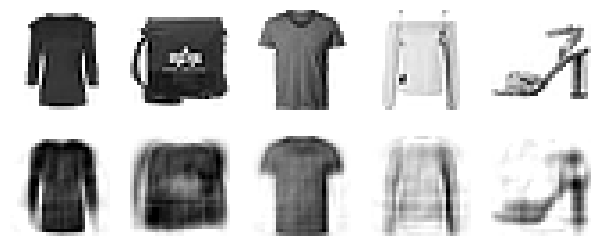

In [26]:
plot_reconstructions(sparse_l1_ae)
plt.show()

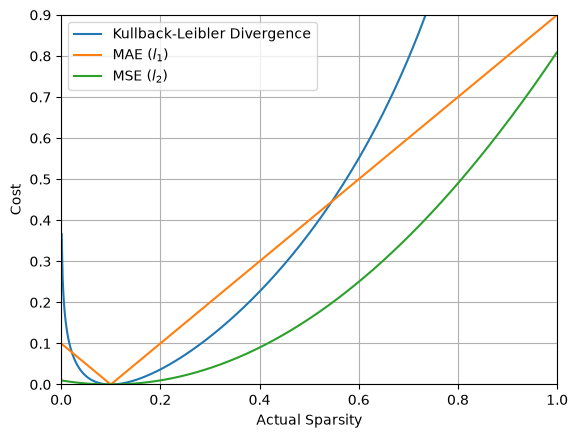

In [27]:
p = 0.1
q = np.linspace(0.001, 0.999, 500)
kl_div = p * np.log(p / q) + (1-p) * np.log((1-p) / (1-q))
mae = np.abs(p - q)
mse = (p - q) ** 2

plt.plot(q, kl_div, label='Kullback-Leibler Divergence')
plt.plot(q, mae, label='MAE ($l_1$)')
plt.plot(q, mse, label='MSE ($l_2$)')
plt.xlabel('Actual Sparsity')
plt.ylabel('Cost')
plt.xlim(0, 1)
plt.ylim(0, 0.9)
plt.grid()
plt.legend()
plt.show()

In [28]:
kl_divergence = tf.keras.losses.kullback_leibler_divergence

class KLDivergenceRegularizer(tf.keras.regularizers.Regularizer):
    def __init__(self, weight, target):
        self.weight = weight
        self.target = target

    def __call__(self, inputs):
        mean_activities = tf.reduce_mean(inputs, axis=0)
        return self.weight * (
            kl_divergence(self.target, mean_activities) +
            kl_divergence(1. - self.target, 1. - mean_activities))

In [29]:
tf.random.set_seed(42)

kld_reg = KLDivergenceRegularizer(weight=5e-3, target=0.1)

sparse_kl_encoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(300, activation='sigmoid',
                          activity_regularizer=kld_reg)
])

sparse_kl_decoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(300,)),
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(28 * 28),
    tf.keras.layers.Reshape((28, 28))
])

sparse_kl_ae = tf.keras.models.Sequential([sparse_kl_encoder, sparse_kl_decoder])
sparse_kl_ae.compile(loss='mse', optimizer='nadam')
history = sparse_kl_ae.fit(X_train, X_train, epochs=10, validation_data=(X_valid, X_valid))

Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.0252 - val_loss: 0.0170
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0149 - val_loss: 0.0135
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 0.0125 - val_loss: 0.0119
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.0114 - val_loss: 0.0110
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.0107 - val_loss: 0.0105
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.0103 - val_loss: 0.0104
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 0.0100 - val_loss: 0.0101
Epoch 8/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - loss: 0.0098 - val_loss: 0.0099
Epoch 9/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 0.0097 - val_loss: 0.0097
Epoch 10/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.0096 - val_loss: 0.0096


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


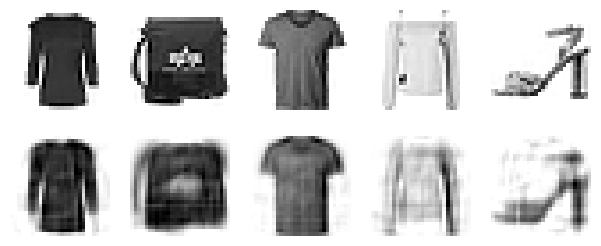

In [30]:
plot_reconstructions(sparse_kl_ae)
plt.show()

## 17.7 변이형 오토인코더

In [31]:
class Sampling(tf.keras.layers.Layer):
    def call(self, inputs):
        mean, log_var = inputs
        return tf.random.normal(tf.shape(log_var)) * tf.exp(log_var / 2) + mean

In [32]:
tf.random.set_seed(42)

codings_size = 10
inputs = tf.keras.layers.Input(shape=(28, 28))
Z = tf.keras.layers.Flatten()(inputs)
Z = tf.keras.layers.Dense(150, activation='relu')(Z)
Z = tf.keras.layers.Dense(100, activation='relu')(Z)
codings_mean = tf.keras.layers.Dense(codings_size)(Z)
codings_log_var = tf.keras.layers.Dense(codings_size)(Z)
codings = Sampling()((codings_mean, codings_log_var))

variational_encoder = tf.keras.models.Model(
    inputs=[inputs], outputs=[codings_mean, codings_log_var, codings])

In [33]:
decoder_inputs = tf.keras.layers.Input(shape=(codings_size,))
x = tf.keras.layers.Dense(100, activation='relu')(decoder_inputs)
x = tf.keras.layers.Dense(150, activation='relu')(x)
x = tf.keras.layers.Dense(28 * 28)(x)
outputs = tf.keras.layers.Reshape((28, 28))(x)

variational_decoder = tf.keras.models.Model(inputs=[decoder_inputs], outputs=[outputs])

In [34]:
class VariantionalAutoencoder(tf.keras.models.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

    def call(self, inputs):
        codings_mean, codings_log_var, codings = self.encoder(inputs)
        reconstructions = self.decoder(codings)
        latent_loss = -0.5 * tf.reduce_sum(
            1 + codings_log_var - tf.exp(codings_log_var) - tf.square(codings_mean),
            axis=-1)
        self.add_loss(tf.reduce_mean(latent_loss) / 784.)
        return reconstructions

In [35]:
variational_ae = VariantionalAutoencoder(variational_encoder, variational_decoder)
variational_ae.compile(loss='mse', optimizer='nadam')
history = variational_ae.fit(X_train, X_train, epochs=25, batch_size=128,
                             validation_data=(X_valid, X_valid))

Epoch 1/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.0502 - val_loss: 0.0389
Epoch 2/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0367 - val_loss: 0.0357
Epoch 3/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0348 - val_loss: 0.0347
Epoch 4/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0338 - val_loss: 0.0337
Epoch 5/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0333 - val_loss: 0.0333
Epoch 6/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0329 - val_loss: 0.0329
Epoch 7/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0326 - val_loss: 0.0327
Epoch 8/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0323 - val_loss: 0.0325
Epoch 9/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0321 - val_loss: 0.0324
Epoch 10/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0319 - val_loss: 0.0321
Epoch 11/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0318 - val_loss: 0.0320
Epoch 12/25
430/430 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step


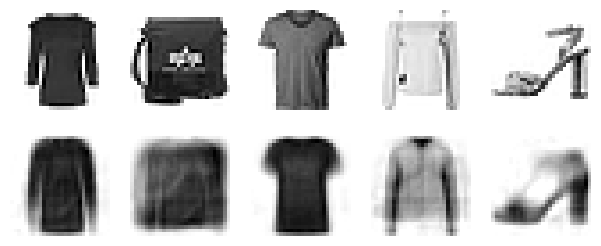

In [36]:
plot_reconstructions(variational_ae)
plt.show()

### 17.7.1 패션 MNIST 이미지 생성하기

In [37]:
def plot_multiple_images(images, n_cols=None):
    n_cols = n_cols or len(images)
    n_rows = (len(images) - 1) // n_cols + 1
    if images.shape[-1] == 1:
        images = images.squeeze(axis=-1)
    plt.figure(figsize=(n_cols, n_rows))
    for index, image in enumerate(images):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(image, cmap='binary')
        plt.axis('off')

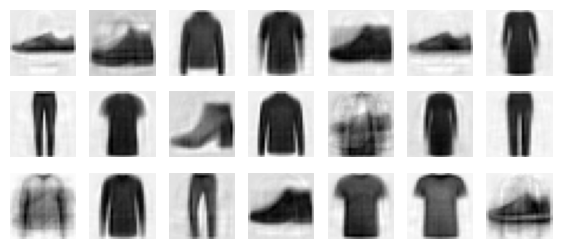

In [38]:
tf.random.set_seed(42)

codings = tf.random.normal(shape=(21, codings_size))
images = variational_decoder(codings).numpy()

plot_multiple_images(images, 7)
plt.show()

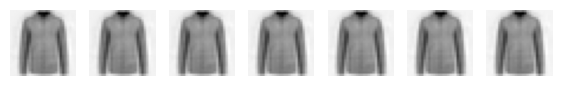

In [39]:
tf.random.set_seed(42)

codings = np.zeros([7, codings_size])
codings[:, 1] = np.linspace(-0.8, 0.8, 7)
images = variational_decoder(codings).numpy()

plot_multiple_images(images, 7)
plt.show()

## 17.8 생성적 적대 신경망

In [40]:
tf.random.set_seed(42)

codings_size = 30
Dense = tf.keras.layers.Dense

generator = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(codings_size,)),
    Dense(100, activation='relu', kernel_initializer='he_normal'),
    Dense(150, activation='relu', kernel_initializer='he_normal'),
    Dense(28 * 28, activation='sigmoid'),
    tf.keras.layers.Reshape((28, 28))
])

discriminator = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    Dense(150, activation='relu', kernel_initializer='he_normal'),
    Dense(100, activation='relu', kernel_initializer='he_normal'),
    Dense(1, activation='sigmoid')
])

gan = tf.keras.models.Sequential([generator, discriminator])

In [41]:
discriminator.compile(loss='binary_crossentropy', optimizer='rmsprop')
gan.compile(loss='binary_crossentropy', optimizer='rmsprop')

In [42]:
batch_size = 32
dataset = tf.data.Dataset.from_tensor_slices(X_train).shuffle(1000)
dataset = dataset.batch(batch_size, drop_remainder=True).prefetch(1)

Epochs 1/10


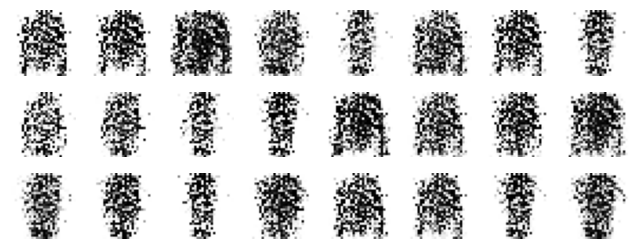

Epochs 2/10


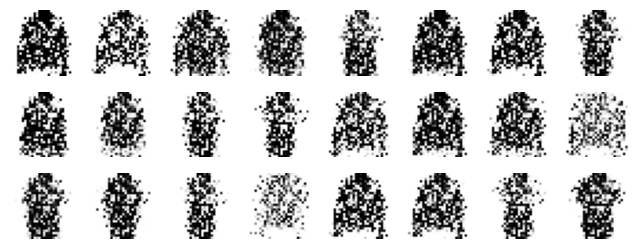

Epochs 3/10


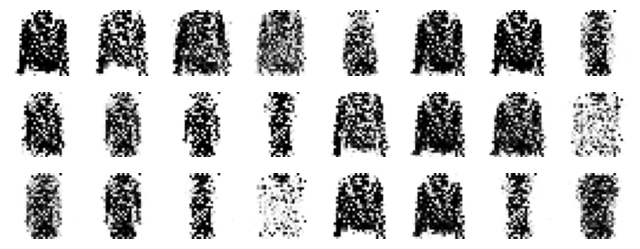

Epochs 4/10


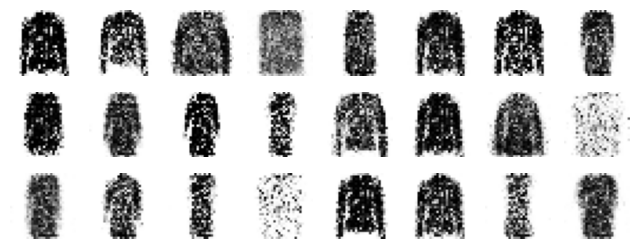

Epochs 5/10


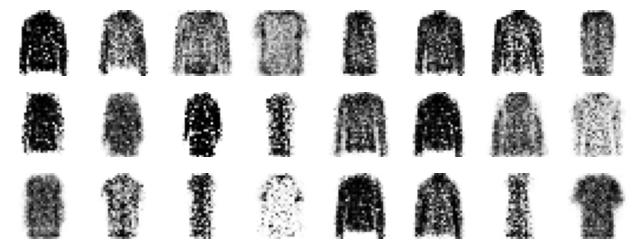

Epochs 6/10


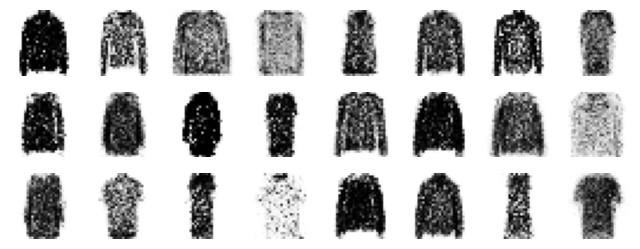

Epochs 7/10


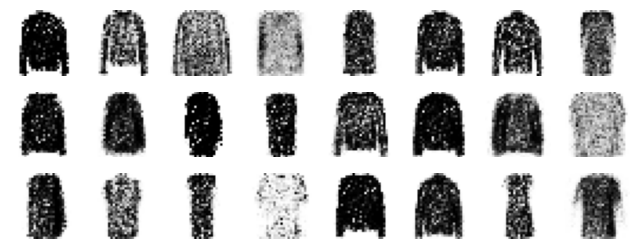

Epochs 8/10


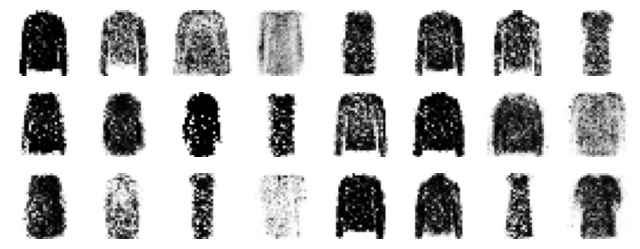

Epochs 9/10


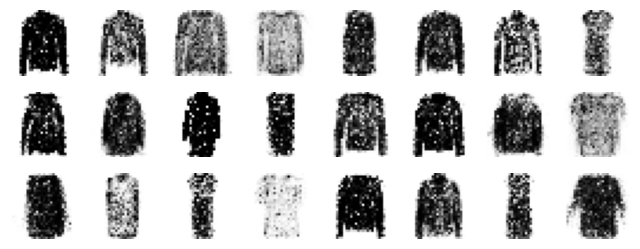

Epochs 10/10


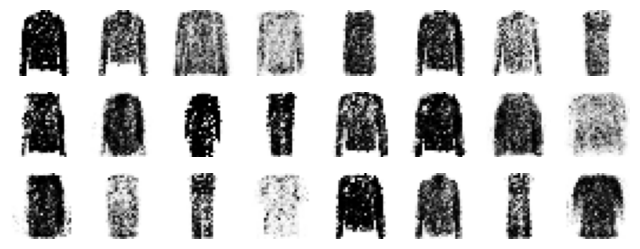

In [43]:
def train_gan(gan, dataset, batch_size, codings_size, n_epochs, verbose=0):
    test_noise = tf.random.normal(shape=(24, codings_size))
    
    generator, discriminator = gan.layers
    for epoch in range(n_epochs):
        if verbose >= 1:
            print(f'Epochs {epoch + 1}/{n_epochs}')
        
        for X_batch in dataset:
            # Training discriminator
            noise = tf.random.normal(shape=(batch_size, codings_size))
            generated_images = generator(noise)
            X_fake_and_real = tf.concat([generated_images, X_batch], axis=0)
            y1 = tf.constant([[0.]] * batch_size + [[1.]] * batch_size)
            discriminator.trainable = True
            discriminator.train_on_batch(X_fake_and_real, y1)

            # Training generator
            noise = tf.random.normal(shape=(batch_size, codings_size))
            y2 = tf.constant([[1.]] * batch_size)
            discriminator.trainable = False
            gan.train_on_batch(noise, y2)

        if verbose >= 2:
            test_images = generator(test_noise, training=False).numpy().copy()
            plot_multiple_images(test_images, 8)
            plt.show()

train_gan(gan, dataset, batch_size, codings_size, n_epochs=10, verbose=2)

### 17.8.2 심층 합성곱 GAN

In [44]:
tf.random.set_seed(42)

codings_size = 100

generator = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(codings_size,)),
    tf.keras.layers.Dense(7 * 7 * 128),
    tf.keras.layers.Reshape((7, 7, 128)), # (7, 7, 128)
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2DTranspose(64, kernel_size=5, strides=2,
                                    padding='same', activation='relu'), # (14, 14, 64)
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2DTranspose(1, kernel_size=5, strides=2,
                                    padding='same', activation='tanh')  # (28, 28, 1)
])

discriminator = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(64, kernel_size=5, strides=2, padding='same',
                           activation=tf.keras.layers.LeakyReLU(0.2)),  # (14, 14, 64)
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Conv2D(128, kernel_size=5, strides=2, padding='same',
                           activation=tf.keras.layers.LeakyReLU(0.2)),  # (28, 28, 128)
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Flatten(),  # (28 * 28 * 128,)
    tf.keras.layers.Dense(1, activation='sigmoid')
])

gan = tf.keras.models.Sequential([generator, discriminator])

In [45]:
discriminator.compile(loss='binary_crossentropy', optimizer='rmsprop')
gan.compile(loss='binary_crossentropy', optimizer='rmsprop')

In [46]:
X_train_dcgan = X_train.reshape(-1, 28, 28, 1) * 2. - 1.

Epochs 1/10


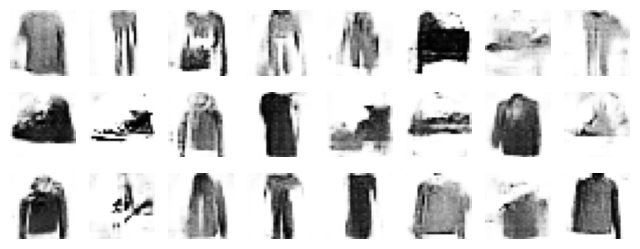

Epochs 2/10


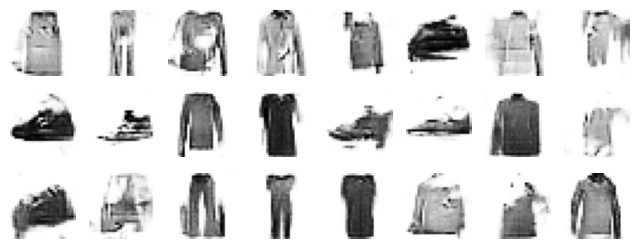

Epochs 3/10


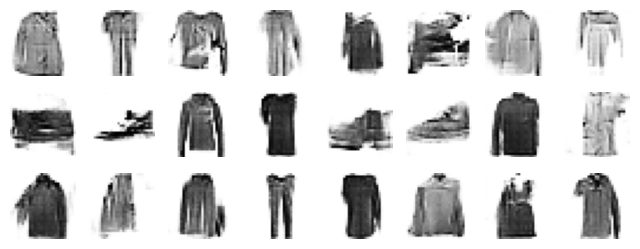

Epochs 4/10


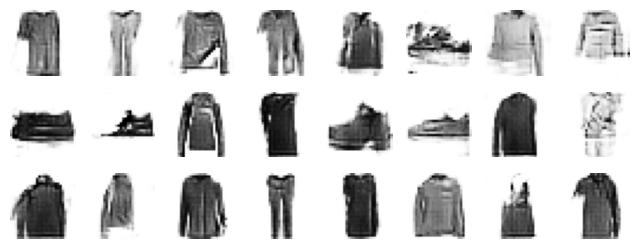

Epochs 5/10


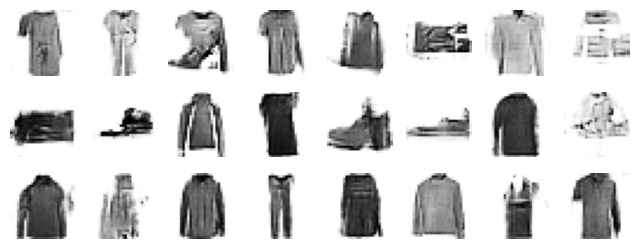

Epochs 6/10


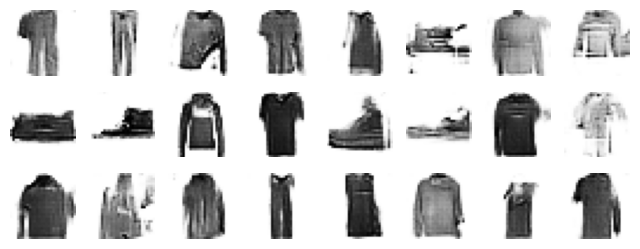

Epochs 7/10


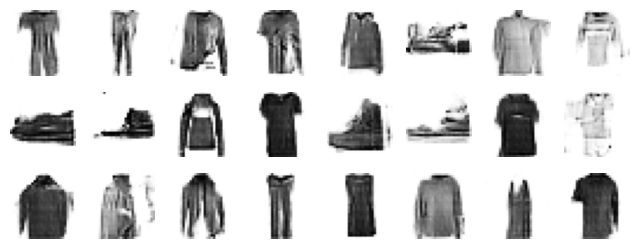

Epochs 8/10


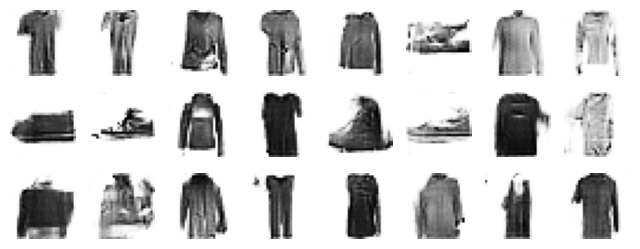

Epochs 9/10


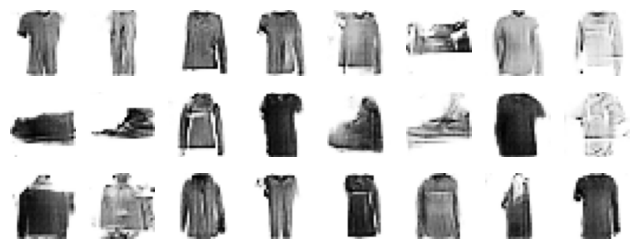

Epochs 10/10


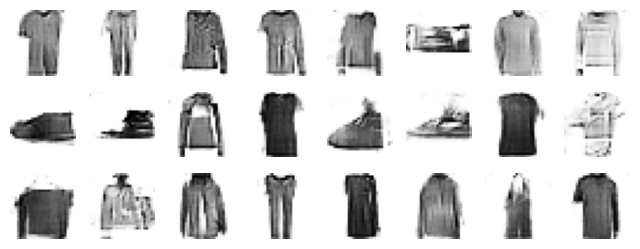

In [47]:
batch_size = 32
dataset = tf.data.Dataset.from_tensor_slices(X_train_dcgan).shuffle(1000)\
    .batch(batch_size, drop_remainder=True).prefetch(1)

train_gan(gan, dataset, batch_size, codings_size, n_epochs=10, verbose=2)

## 17.9 확산 모델

In [48]:
def variance_schedule(T, s=0.008, max_beta=0.999):
    t = np.arange(T + 1)
    f = np.cos((t / T + s) / (1 + s) * np.pi / 2) ** 2
    alpha = np.clip(f[1:] / f[:-1], 1 - max_beta, 1)
    alpha = np.append(1, alpha).astype(np.float32)
    beta = 1 - alpha
    alpha_cumprod = np.cumprod(alpha)
    return alpha, alpha_cumprod, beta

T = 4000
alpha, alpha_cumprod, beta = variance_schedule(T)

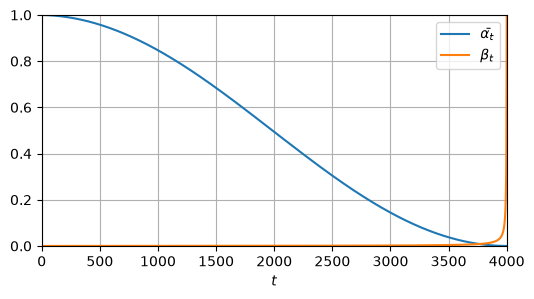

In [49]:
plt.figure(figsize=(6, 3))
plt.plot(alpha_cumprod, label=r'$\bar{\alpha_t}$')
plt.plot(beta, label=r'$\beta_t$')
plt.legend()
plt.xlabel('$t$')
plt.grid()
plt.axis([0, T, 0, 1])
plt.show()

In [50]:
def prepare_batch(X):
    X = tf.cast(X[..., tf.newaxis], tf.float32) * 2 - 1
    X_shape = tf.shape(X)
    t = tf.random.uniform([X_shape[0]], minval=1, maxval=T + 1, dtype=tf.int32)
    alpha_cm = tf.gather(alpha_cumprod, t)
    alpha_cm = tf.reshape(alpha_cm, [X_shape[0]] + [1] * (len(X_shape) - 1))
    noise = tf.random.normal(X_shape)
    return {
        'X_noisy': alpha_cm ** 0.5 * X + (1 - alpha_cm) ** 0.5 * noise,
        'time': t
    }, noise

In [51]:
tf.random.set_seed(42)

def prepare_dataset(X, batch_size=32, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(X)
    if shuffle:
        ds = ds.shuffle(10_000)
    return ds.batch(batch_size).map(prepare_batch).prefetch(1)

train_set = prepare_dataset(X_train, shuffle=True)
valid_set = prepare_dataset(X_valid)

Orinial Images


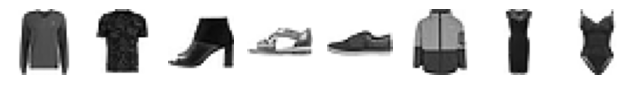

Time steps: [2644 3772 3918 1208 3304 2526 2095 2652]
Noisy images


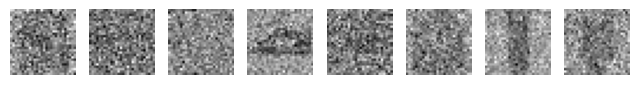

Noise


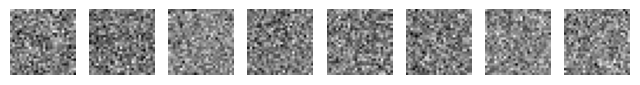

In [52]:
def subtract_noise(X_noisy, time, noise):
    X_shape = tf.shape(X_noisy)
    alpha_cm = tf.gather(alpha_cumprod, time)
    alpha_cm = tf.reshape(alpha_cm, [X_shape[0]] + [1] * (len(X_shape) - 1))
    return (X_noisy - (1 - alpha_cm) ** 0.5 * noise) / (alpha_cm ** 0.5)  

X_dict, Y_noise = list(train_set.take(1))[0]
X_original = subtract_noise(X_dict['X_noisy'], X_dict['time'], Y_noise)

print('Orinial Images')
plot_multiple_images(X_original[:8].numpy(), 8)
plt.show()
print('Time steps:', X_dict['time'][:8].numpy())
print('Noisy images')
plot_multiple_images(X_dict['X_noisy'][:8].numpy(), 8)
plt.show()
print('Noise')
plot_multiple_images(Y_noise[:8].numpy(), 8)
plt.show()

In [53]:
embed_size = 64

@tf.keras.utils.register_keras_serializable()
class TimeEncoding(tf.keras.layers.Layer):
    def __init__(self, T, embed_size, dtype=tf.float32, **kwargs):
        super().__init__(dtype=dtype, **kwargs)
        assert embed_size % 2 == 0, 'embed_size must be even'
        self.T = T
        self.embed_size = embed_size
        
        p, i = np.meshgrid(np.arange(T + 1), 2 * np.arange(embed_size // 2))
        t_emb = np.empty((T + 1, embed_size))
        t_emb[:, ::2] = np.sin(p / 10_000 ** (i / embed_size)).T
        t_emb[:, 1::2] = np.cos(p / 10_000 ** (i / embed_size)).T
        self.time_encodings = tf.constant(t_emb.astype(self.dtype))

    def call(self, inputs):
        return tf.gather(self.time_encodings, inputs)

    def get_config(self):
        super_config = super().get_config()
        return {'T': self.T, 'embed_size': self.embed_size, **super_config}

In [54]:
def build_diffusion_model(T=T, embed_size=embed_size):
    X_noisy = tf.keras.layers.Input(shape=(28, 28, 1), name='X_noisy')
    time_input = tf.keras.layers.Input(shape=(), dtype=tf.int32, name='time')
    time_enc = TimeEncoding(T, embed_size)(time_input)  # (batch, embed_size)

    dim = 16
    Z = tf.keras.layers.ZeroPadding2D((3, 3))(X_noisy)  # (batch, 34, 34, 1)
    Z = tf.keras.layers.Conv2D(dim, 3)(Z)               # (batch, 32, 32, 16) 
    Z = tf.keras.layers.BatchNormalization()(Z)
    Z = tf.keras.layers.Activation('relu')(Z)

    time = tf.keras.layers.Dense(dim)(time_enc)  # (batch, 16)
    time = time[:, tf.newaxis, tf.newaxis, :]    # (batch, 1, 1, 16)
    Z = tf.keras.layers.Add()([Z, time])                # (batch, 32, 32, 16)

    cross_skips = []
    skip = Z
    for dim in (32, 64, 128):
        # A = (32, 16, 8)
        # B = (16, 8, 4)
        Z = tf.keras.layers.Activation('relu')(Z)
        Z = tf.keras.layers.SeparableConv2D(dim, 3, padding='same')(Z)    # (batch, A, A, dim)
        Z = tf.keras.layers.BatchNormalization()(Z)

        Z = tf.keras.layers.Activation('relu')(Z)
        Z = tf.keras.layers.SeparableConv2D(dim, 3, padding='same')(Z)
        Z = tf.keras.layers.BatchNormalization()(Z)
        
        cross_skips.append(Z)
        Z = tf.keras.layers.MaxPooling2D(3, strides=2, padding='same')(Z) # (batch, B, B, dim)
        skip_link = tf.keras.layers.Conv2D(dim, 1, strides=2, padding='same')(skip)
        Z = tf.keras.layers.Add()([Z, skip_link])

        time = tf.keras.layers.Dense(dim)(time_enc)  # (batch, dim)
        time = time[:, tf.newaxis, tf.newaxis, :]    # (batch, 1, 1, dim)
        Z = tf.keras.layers.Add()([Z, time])                              # (batch, B, B, dim)
        skip = Z

    for dim in (64, 32, 16):
        # C = (4, 8, 16)
        # D = (8, 16, 32)
        Z = tf.keras.layers.Activation('relu')(Z)
        Z = tf.keras.layers.Conv2DTranspose(dim, 3, padding='same')(Z)  # (batch, C, C, dim)
        Z = tf.keras.layers.BatchNormalization()(Z)

        Z = tf.keras.layers.Activation('relu')(Z)
        Z = tf.keras.layers.Conv2DTranspose(dim, 3, padding='same')(Z)
        Z = tf.keras.layers.BatchNormalization()(Z)

        Z = tf.keras.layers.UpSampling2D(2)(Z)                          # (batch, D, D, dim)

        skip_link = tf.keras.layers.UpSampling2D(2)(skip)   # (batch, D, D, dim)
        skip_link = tf.keras.layers.Conv2D(dim, 1, padding='same')(skip_link)
        Z = tf.keras.layers.Add()([Z, skip_link])                       # (batch, D, D, dim)
        
        time = tf.keras.layers.Dense(dim)(time_enc)  # (batch, dim)
        time = time[:, tf.newaxis, tf.newaxis, :]    # (batch, 1, 1, dim)
        Z = tf.keras.layers.Add()([Z, time])

        Z = tf.keras.layers.Concatenate()([Z, cross_skips.pop()])       # (batch, D, D, dim)
        skip = Z

    # Z.shape = (batch, 32, 32, 16)   outputs.shape = (batch, 28, 28, 16)
    outputs = tf.keras.layers.Conv2D(1, 3, padding='same')(Z)[:, 2:-2, 2:-2, :]

    return tf.keras.models.Model(inputs=[X_noisy, time_input], outputs=[outputs])

In [55]:
tf.random.set_seed(42)

model = build_diffusion_model()
model.compile(loss=tf.keras.losses.Huber(), optimizer='nadam')

checkpoint_cb = tf.keras.callbacks.ModelCheckpoint('my_diffusion_model.keras',
                                                   save_best_only=True)
history = model.fit(train_set, epochs=100, validation_data=valid_set,
                    callbacks=[checkpoint_cb])

Epoch 1/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 162s 90ms/step - loss: 0.1019 - val_loss: 0.0696
Epoch 2/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 154s 90ms/step - loss: 0.0603 - val_loss: 0.0565
Epoch 3/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 152s 88ms/step - loss: 0.0525 - val_loss: 0.0500
Epoch 4/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 151s 88ms/step - loss: 0.0489 - val_loss: 0.0475
Epoch 5/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 152s 88ms/step - loss: 0.0469 - val_loss: 0.0464
Epoch 6/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 154s 90ms/step - loss: 0.0454 - val_loss: 0.0448
Epoch 7/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 153s 89ms/step - loss: 0.0444 - val_loss: 0.0441
Epoch 8/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 155s 90ms/step - loss: 0.0436 - val_loss: 0.0445
Epoch 9/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 155s 90ms/step - loss: 0.0431 - val_loss: 0.0425
Epoch 10/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 155s 90ms/step - loss: 0.0427 - val_loss: 0.0421
Epoch 11/100
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 155s 90ms/step - loss: 0.0422 - val

In [56]:
def generate(model, batch_size=32):
    X = tf.random.normal((batch_size, 28, 28, 1))
    for t in range(T, 0, -1):
        noise = (tf.random.normal if t > 1 else tf.zeros)(tf.shape(X))
        X_noise = model({'X_noisy': X, 'time': tf.constant([t] * batch_size)})
        X = (
            1 / alpha[t] ** 0.5
            * (X - beta[t] / (1 - alpha_cumprod[t]) ** 0.5 * X_noise)
            + beta[t] ** 0.5 * noise
        )
    return X

tf.random.set_seed(42)
X_gen = generate(model)

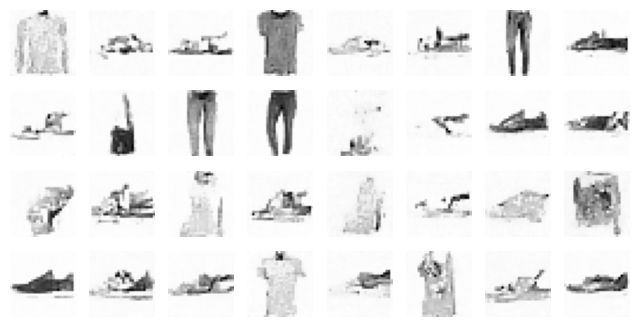

In [57]:
plot_multiple_images(X_gen.numpy(), 8)
plt.show()

## 연습문제

### ⑩

#### Step A

In [58]:
(X_train, y_train), (X_valid, y_valid) = tf.keras.datasets.cifar10.load_data()
X_train = X_train / 255
X_valid = X_valid / 255

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 211s 1us/step


In [59]:
tf.random.set_seed(42)

denoising_encoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    tf.keras.layers.GaussianNoise(0.1),
    tf.keras.layers.Conv2D(32, 3, padding='same', activation='relu'),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(512, activation='relu')
])

denoising_decoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(512,)),
    tf.keras.layers.Dense(16 * 16 * 32, activation='relu'),
    tf.keras.layers.Reshape((16, 16, 32)),
    tf.keras.layers.Conv2DTranspose(3, 3, strides=2, padding='same', activation='sigmoid')
])

denoising_ae = tf.keras.models.Sequential([denoising_encoder, denoising_decoder])
denoising_ae.compile(loss='binary_crossentropy', optimizer='nadam', metrics=['mse'])
history = denoising_ae.fit(X_train, X_train, epochs=10, validation_data=(X_valid, X_valid))

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 71s 44ms/step - loss: 0.5867 - mse: 0.0158 - val_loss: 0.6071 - val_mse: 0.0218
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 69s 44ms/step - loss: 0.5707 - mse: 0.0090 - val_loss: 0.5930 - val_mse: 0.0163
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 69s 44ms/step - loss: 0.5681 - mse: 0.0081 - val_loss: 0.6065 - val_mse: 0.0203
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 68s 44ms/step - loss: 0.5670 - mse: 0.0077 - val_loss: 0.5816 - val_mse: 0.0120
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 70s 45ms/step - loss: 0.5662 - mse: 0.0074 - val_loss: 0.5743 - val_mse: 0.0097
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 72s 46ms/step - loss: 0.5657 - mse: 0.0073 - val_loss: 0.5722 - val_mse: 0.0091
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 69s 44ms/step - loss: 0.5653 - mse: 0.0071 - val_loss: 0.5706 - val_mse: 0.0086
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 69s 44ms/step - loss: 0.5650 - mse: 0.0070 - val_loss: 0.5677 - val_mse: 0.0076
Epoch 9/10
1563/1563 ━━━

#### Step B

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


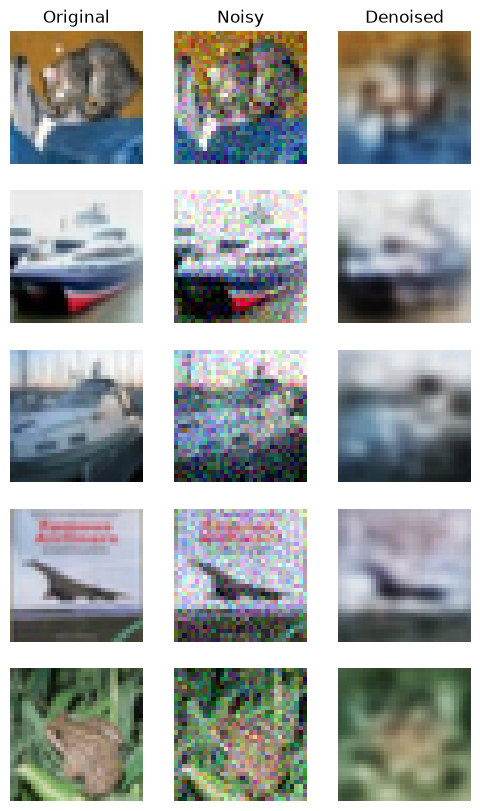

In [60]:
n_images = 5
new_images = X_valid[:n_images]
new_images_noisy = np.clip(new_images + np.random.randn(n_images, 32, 32, 3) * 0.1, 0, 1)
new_images_denoised = denoising_ae.predict(new_images_noisy)

plt.figure(figsize=(6, n_images * 2))
for idx in range(n_images):
    plt.subplot(n_images, 3, idx * 3 + 1)
    plt.imshow(new_images[idx])
    plt.axis('off')
    if idx == 0:
        plt.title('Original')

    plt.subplot(n_images, 3, idx * 3 + 2)
    plt.imshow(new_images_noisy[idx])
    plt.axis('off')
    if idx == 0:
        plt.title('Noisy')

    plt.subplot(n_images, 3, idx * 3 + 3)
    plt.imshow(new_images_denoised[idx])
    plt.axis('off')
    if idx == 0:
        plt.title('Denoised')
plt.show()

#### Step C

In [61]:
X_train_500 = X_train[:500]
y_train_500 = y_train[:500]
X_valid_500 = X_valid[:500]
y_valid_500 = y_valid[:500]

In [62]:
tf.random.set_seed(42)

classifier_scratch = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    tf.keras.layers.Conv2D(32, 3, padding='same'),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])
classifier_scratch.compile(loss='sparse_categorical_crossentropy',
                           optimizer='nadam', metrics=['accuracy'])
history = classifier_scratch.fit(X_train_500, y_train_500, epochs=10,
                                 validation_data=(X_valid_500, y_valid_500))

Epoch 1/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.1260 - loss: 2.3791 - val_accuracy: 0.1440 - val_loss: 2.2725
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1740 - loss: 2.2250 - val_accuracy: 0.2400 - val_loss: 2.2011
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.2600 - loss: 2.0796 - val_accuracy: 0.2620 - val_loss: 2.0999
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3140 - loss: 1.9408 - val_accuracy: 0.2640 - val_loss: 2.0556
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3820 - loss: 1.7818 - val_accuracy: 0.2780 - val_loss: 2.0010
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4240 - loss: 1.6413 - val_accuracy: 0.3000 - val_loss: 1.9560
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.4960 - loss: 1.5041 - val_accuracy: 0.3020 - val_loss: 1.9167
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5500 - loss: 1.3618 - val_accuracy: 0.3380 - v

In [63]:
tf.random.set_seed(42)

pretrained_encoder = tf.keras.models.clone_model(denoising_encoder)
pretrained_encoder.set_weights(denoising_encoder.get_weights())
pretrained_encoder.training = False

classifier = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    pretrained_encoder,
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])
classifier.compile(loss='sparse_categorical_crossentropy',
                   optimizer='nadam', metrics=['accuracy'])
history = classifier.fit(X_train_500, y_train_500, epochs=10,
                         validation_data=(X_valid_500, y_valid_500))

Epoch 1/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.1160 - loss: 2.3937 - val_accuracy: 0.1220 - val_loss: 2.2560
Epoch 2/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.1760 - loss: 2.1326 - val_accuracy: 0.1680 - val_loss: 2.1692
Epoch 3/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.2900 - loss: 1.9111 - val_accuracy: 0.2260 - val_loss: 2.1039
Epoch 4/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.3980 - loss: 1.6582 - val_accuracy: 0.2640 - val_loss: 2.0347
Epoch 5/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.5220 - loss: 1.4393 - val_accuracy: 0.2760 - val_loss: 1.9949
Epoch 6/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6000 - loss: 1.2419 - val_accuracy: 0.3000 - val_loss: 1.9808
Epoch 7/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.6520 - loss: 1.0792 - val_accuracy: 0.2940 - val_loss: 1.9862
Epoch 8/10
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.7180 - loss: 0.9049 - val_accuracy: 0.2960 - v

### ⑪

In [64]:
fashion_mnist = tf.keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist
X_train_full = X_train_full.astype(np.float32) / 255
X_test = X_test.astype(np.float32) / 255
X_train, X_valid = X_train_full[:-5000], X_train_full[-5000:]
y_train, y_valid = y_train_full[:-5000], y_train_full[-5000:]

X_train = X_train[..., np.newaxis]
X_valid = X_valid[..., np.newaxis]
X_test = X_test[..., np.newaxis]

In [65]:
class Sampling(tf.keras.layers.Layer):
    def call(self, inputs):
        mean, log_var = inputs
        return tf.random.normal(tf.shape(log_var)) * tf.exp(log_var) + mean

In [66]:
tf.random.set_seed(42)

encoder_inputs = tf.keras.layers.Input(shape=(28, 28, 1))
Z = tf.keras.layers.Conv2D(16, 3, padding='same')(encoder_inputs)
Z = tf.keras.layers.MaxPooling2D(2)(Z)   # (14, 14, 16)
Z = tf.keras.layers.Conv2D(32, 3, padding='same')(Z)
Z = tf.keras.layers.MaxPooling2D(2)(Z)   # (7, 7, 32)
Z = tf.keras.layers.Flatten()(Z)
Z = tf.keras.layers.Dense(256, activation='relu')(Z)
Z = tf.keras.layers.Dense(128, activation='relu')(Z)
Z = tf.keras.layers.Dense(64, activation='relu')(Z)
mean = tf.keras.layers.Dense(10)(Z)
log_var = tf.keras.layers.Dense(10)(Z)
encoder_outputs = Sampling()((mean, log_var))

variational_encoder = tf.keras.models.Model(inputs=[encoder_inputs],
                                            outputs=[mean, log_var, encoder_outputs])

In [67]:
variational_decoder = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(10,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(7 * 7 * 32),
    tf.keras.layers.Reshape((7, 7, 32)),
    tf.keras.layers.UpSampling2D(2),
    tf.keras.layers.Conv2DTranspose(3, 3, padding='same'),
    tf.keras.layers.UpSampling2D(2),
    tf.keras.layers.Conv2DTranspose(1, 3, padding='same', activation='sigmoid')
])

In [68]:
class VariationalAutoencoder(tf.keras.models.Model):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.encoder = variational_encoder
        self.decoder = variational_decoder
    
    def call(self, inputs):
        mean, log_var, codings = self.encoder(inputs)
        outputs = self.decoder(codings)
        latent_loss = -0.5 * tf.reduce_sum(1 + log_var - tf.exp(log_var) - tf.square(mean),
                                           axis=-1)
        self.add_loss(tf.reduce_mean(latent_loss) / (28 * 28))
        return outputs

variational_ae = VariationalAutoencoder()
variational_ae.compile(loss='binary_crossentropy', optimizer='adam', metrics=['mse'])
history = variational_ae.fit(X_train, X_train, epochs=10, validation_data=(X_valid, X_valid))

Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 22s 12ms/step - loss: 0.3331 - mse: 0.0280 - val_loss: 0.3136 - val_mse: 0.0208
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - loss: 0.3079 - mse: 0.0194 - val_loss: 0.3064 - val_mse: 0.0183
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - loss: 0.3031 - mse: 0.0177 - val_loss: 0.3042 - val_mse: 0.0175
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - loss: 0.3008 - mse: 0.0169 - val_loss: 0.3027 - val_mse: 0.0171
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - loss: 0.2993 - mse: 0.0164 - val_loss: 0.3011 - val_mse: 0.0165
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - loss: 0.2984 - mse: 0.0161 - val_loss: 0.3000 - val_mse: 0.0162
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 20s 12ms/step - loss: 0.2977 - mse: 0.0158 - val_loss: 0.2995 - val_mse: 0.0160
Epoch 8/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - loss: 0.2970 - mse: 0.0156 - val_loss: 0.2989 - val_mse: 0.0159
Epoch 9/10
1719/1719 ━━━

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step


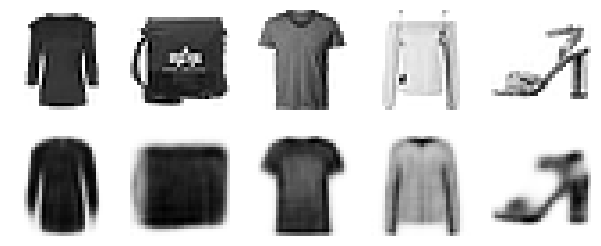

In [69]:
plot_reconstructions(variational_ae)

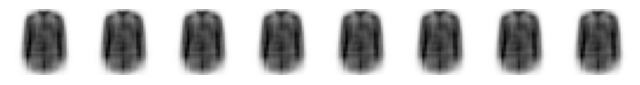

In [70]:
codings = np.zeros((8, 10))
codings[:, 4] = np.linspace(-0.7, 0.7, 8)
images = variational_decoder(codings).numpy()

plot_multiple_images(images, 8)
plt.show()

### ⑫

In [71]:
fashion_mnist = tf.keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist
X_train_full = X_train_full.astype(np.float32) / 255
X_test = X_test.astype(np.float32) / 255

X_train, X_valid = X_train_full[:-5000], X_train_full[-5000:]
y_train, y_valid = y_train_full[:-5000], y_train_full[-5000:]

X_train = X_train[..., np.newaxis] * 2. - 1.
X_valid = X_valid[..., np.newaxis] * 2. - 1.
X_test = X_test[..., np.newaxis] * 2. - 1.

In [72]:
def generate_feature_extractor(n_epochs):
    inputs = tf.keras.layers.Input(shape=(28, 28, 1))
    feature = tf.keras.layers.Dense(128, activation='relu')
    classifier = tf.keras.models.Sequential([
        inputs,
        tf.keras.layers.Conv2D(32, 3, activation='relu'),
        tf.keras.layers.MaxPooling2D(2),
        tf.keras.layers.Conv2D(64, 3, activation='relu'),
        tf.keras.layers.MaxPooling2D(2),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dropout(0.5),
        feature,
        tf.keras.layers.Dense(10, activation='softmax')
    ])

    classifier.compile(loss='sparse_categorical_crossentropy', optimizer='nadam',
                       metrics=['accuracy'])
    earlystopping_cb = tf.keras.callbacks.EarlyStopping(patience=5,
                                                        restore_best_weights=True)
    history = classifier.fit(X_train, y_train, epochs=n_epochs,
                             validation_data=(X_valid, y_valid),
                             callbacks=[earlystopping_cb])

    return tf.keras.models.Model(inputs=[inputs], outputs=feature.output)

tf.random.set_seed(42)
feature_extractor = generate_feature_extractor(n_epochs=20)

Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.8226 - loss: 0.4891 - val_accuracy: 0.8834 - val_loss: 0.3272
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.8747 - loss: 0.3412 - val_accuracy: 0.8998 - val_loss: 0.2829
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.8896 - loss: 0.3011 - val_accuracy: 0.8984 - val_loss: 0.2740
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9000 - loss: 0.2724 - val_accuracy: 0.9056 - val_loss: 0.2625
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9053 - loss: 0.2550 - val_accuracy: 0.9082 - val_loss: 0.2478
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9096 - loss: 0.2420 - val_accuracy: 0.9086 - val_loss: 0.2507
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9140 - loss: 0.2270 - val_accuracy: 0.9120 - val_loss: 0.2414
Epoch 8/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9178 - loss: 0

In [73]:
def generate_dataset(X, batch_size, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices(X)
    if shuffle:
        dataset = dataset.shuffle(10_000)
    return dataset.batch(batch_size, drop_remainder=True).prefetch(1)

batch_size = 32
train_set = generate_dataset(X_train, batch_size, shuffle=True)
valid_set = generate_dataset(X_valid, batch_size)

In [74]:
from scipy.linalg import sqrtm

def calculate_fid(real_features, fake_features):
    mu_real = np.mean(real_features, axis=0)
    mu_fake = np.mean(fake_features, axis=0)
    
    sigma_real = np.cov(real_features, rowvar=False)
    sigma_fake = np.cov(fake_features, rowvar=False)

    diff = mu_real - mu_fake
    covmean = sqrtm(sigma_real @ sigma_fake)
    
    if np.iscomplexobj(covmean):
        covmean = covmean.real

    return (np.sum(diff ** 2) + np.trace(sigma_real)
            + np.trace(sigma_fake) - 2 * np.trace(covmean))

In [75]:
tf.random.set_seed(42)

codings_size = 64

def build_dcgan(codings_size):
    generator = tf.keras.models.Sequential([
        tf.keras.layers.Input(shape=(codings_size,)),
        tf.keras.layers.Dense(7 * 7 * 128),
        tf.keras.layers.Reshape((7, 7, 128)),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Conv2DTranspose(64, 5, strides=2,
                                        padding='same', activation='relu'),  # (14, 14, 64)
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Conv2DTranspose(1, 5, strides=2,
                                        padding='same', activation='tanh')   # (28, 28, 1)
    ])
    
    discriminator = tf.keras.models.Sequential([
        tf.keras.layers.Input(shape=(28, 28, 1)),
        tf.keras.layers.Conv2D(64, 5, strides=2, padding='same',
                               activation=tf.keras.layers.LeakyReLU(0.2)),   # (14, 14, 64)
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Conv2D(128, 5, strides=2, padding='same',
                               activation=tf.keras.layers.LeakyReLU(0.2)),   # (28, 28, 128)
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

    optimizer = tf.keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5)
    discriminator.compile(loss='binary_crossentropy', optimizer=optimizer)
                          
    optimizer = tf.keras.optimizers.Adam(learning_rate=2e-4, beta_1=0.5)
    dcgan = tf.keras.models.Sequential([generator, discriminator])
    dcgan.compile(loss='binary_crossentropy', optimizer=optimizer)
    
    return dcgan

#### DCGAN without ReplayBuffer

Epochs 1/10	FID: 158.70646404683896


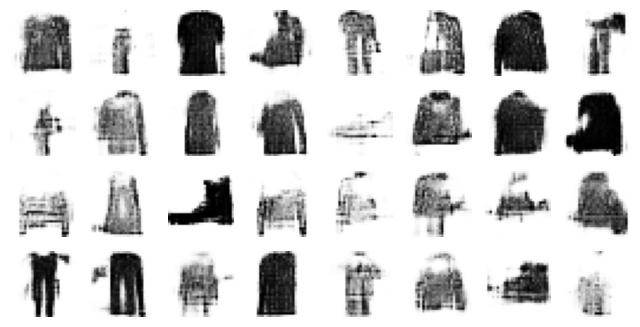

Epochs 2/10	FID: 151.49235263995564


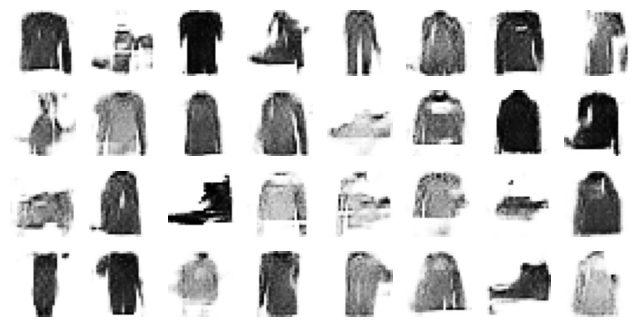

Epochs 3/10	FID: 150.4206915137607


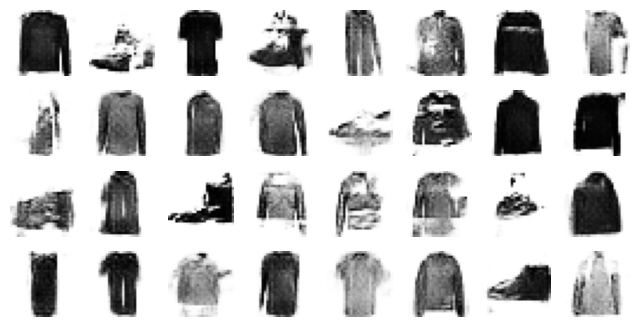

Epochs 4/10	FID: 146.48581406625618


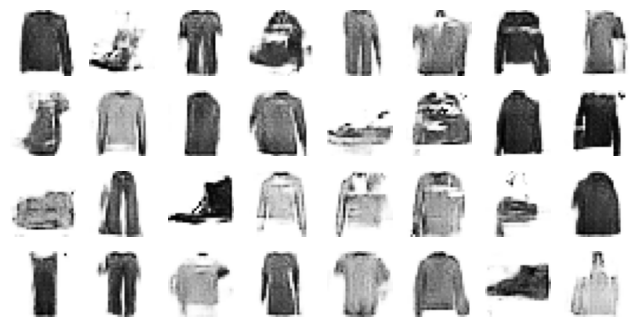

Epochs 5/10	FID: 145.75708451420888


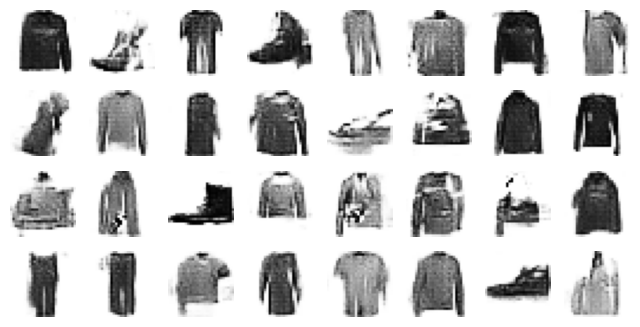

Epochs 6/10	FID: 150.6903891202848


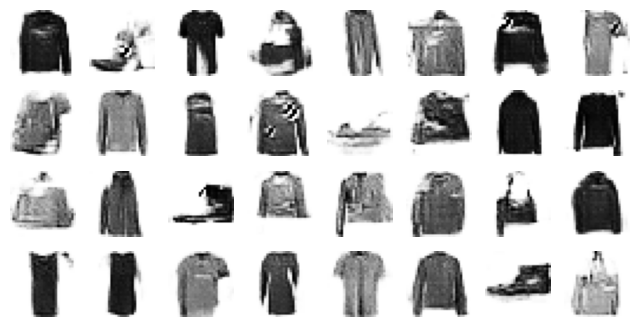

Epochs 7/10	FID: 148.10944150260536


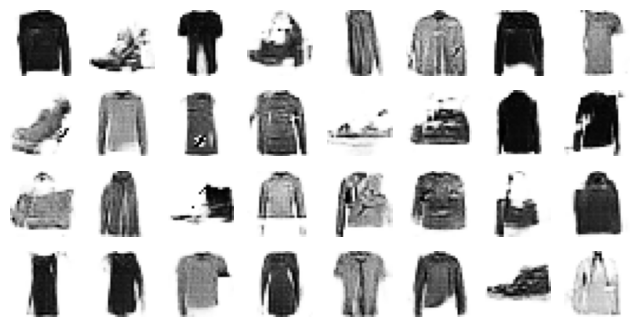

Epochs 8/10	FID: 139.70770750956757


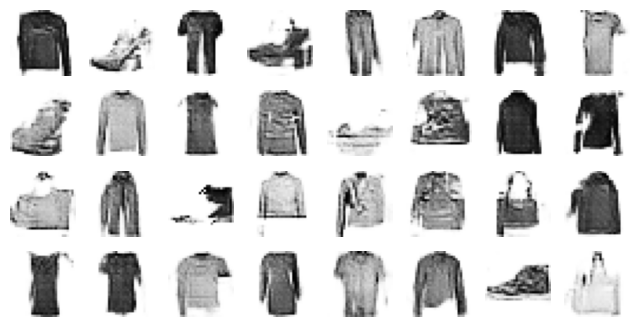

Epochs 9/10	FID: 141.3118020715979


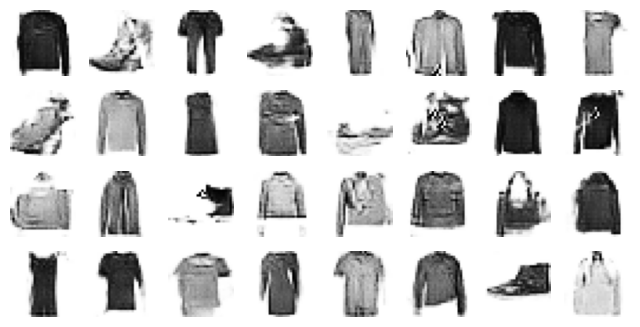

Epochs 10/10	FID: 146.59886126710143


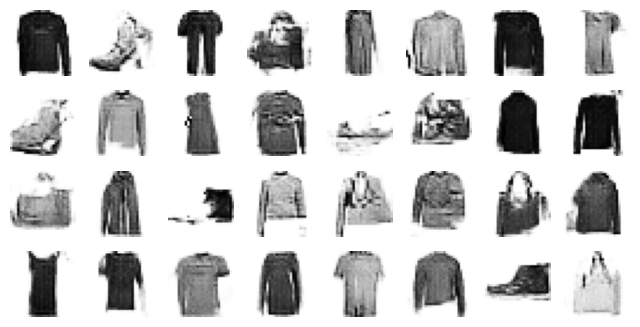

In [76]:
def train_dcgan(dcgan, dataset, X_valid, batch_size,
                feature_extractor, codings_size, n_epochs):
    generator, discriminator = dcgan.layers

    fids = []
    test_noise = tf.random.normal(shape=(batch_size, codings_size))
    real_features = feature_extractor.predict(X_valid[:batch_size], verbose=0)
    
    for epoch in range(n_epochs):
        print(f'Epochs {epoch + 1}/{n_epochs}', end='\t')
        
        for X_batch in dataset:
            noise = tf.random.normal(shape=(batch_size, codings_size))
            generated_images = generator(noise)
            X_fake_and_real = tf.concat([generated_images, X_batch], axis=0)
            y1 = tf.constant([[0.]] * batch_size + [[1.]] * batch_size)
            discriminator.trainable = True
            discriminator.train_on_batch(X_fake_and_real, y1)

            for _ in range(2):
                noise = tf.random.normal(shape=(batch_size, codings_size))
                y2 = tf.constant([[1.]] * batch_size)
                discriminator.trainable = False
                dcgan.train_on_batch(noise, y2)

        fake_images = generator(test_noise, training=False)
        fake_features = feature_extractor.predict(fake_images, verbose=0)

        fid = calculate_fid(real_features, fake_features)
        fids.append(fid)
        print(f'FID: {fid}')
        
        plot_multiple_images(fake_images.numpy().copy(), 8)
        plt.show()

    return fids

tf.random.set_seed(42)
dcgan = build_dcgan(codings_size)
fids = train_dcgan(dcgan, train_set, X_valid, batch_size=batch_size,
                   feature_extractor=feature_extractor, codings_size=codings_size, n_epochs=10)

#### DCGAN with ReplayBuffer

In [77]:
class ReplayBuffer:
    def __init__(self, max_size):
        self.max_size = max_size
        self.buffer = []

    def add(self, images):
        for image in images:
            image = tf.expand_dims(image, axis=0)

            if len(self.buffer) < self.max_size:
                self.buffer.append(image)
            else:
                idx = np.random.randint(self.max_size)
                self.buffer[idx] = image

    def sampling(self, batch_size):
        if len(self.buffer) == 0:
            return None

        size = min(batch_size, len(self.buffer))
        idxes = np.random.choice(len(self.buffer), size=size, replace=False)
        return tf.concat([self.buffer[idx] for idx in idxes], axis=0)

Epochs 1/10	FID: 160.02762654716352


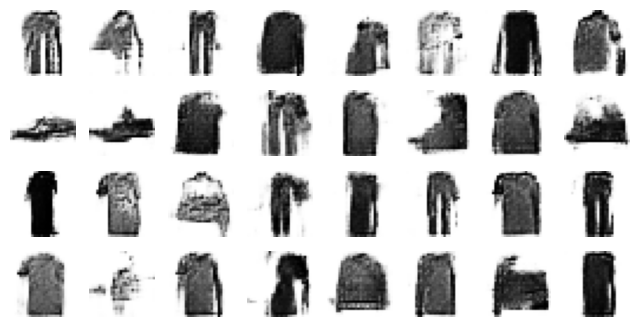

Epochs 2/10	FID: 143.5069796703836


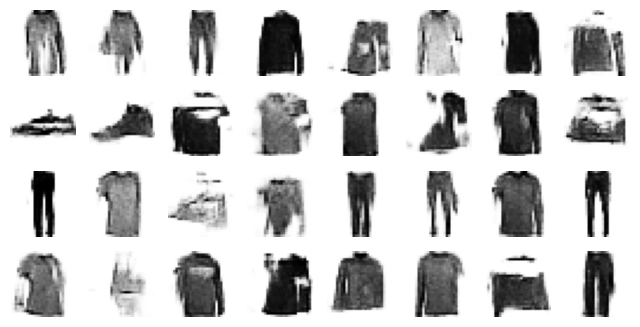

Epochs 3/10	FID: 152.13739774668554


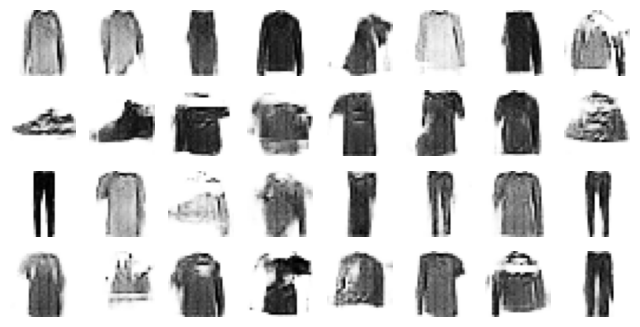

Epochs 4/10	FID: 139.49558744645844


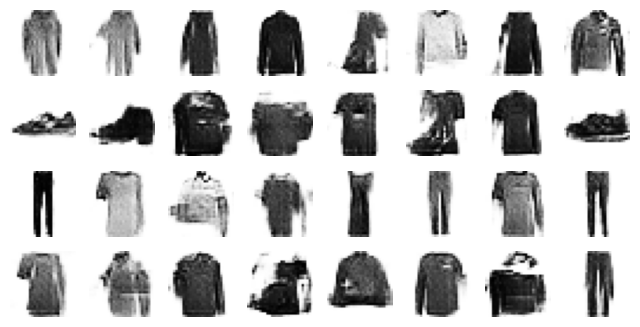

Epochs 5/10	FID: 142.89359862327626


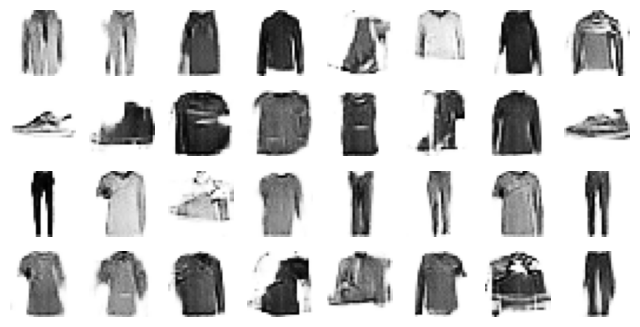

Epochs 6/10	FID: 146.7699165391786


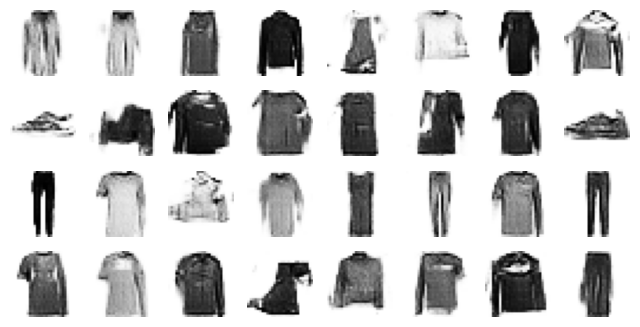

Epochs 7/10	FID: 129.58093058733397


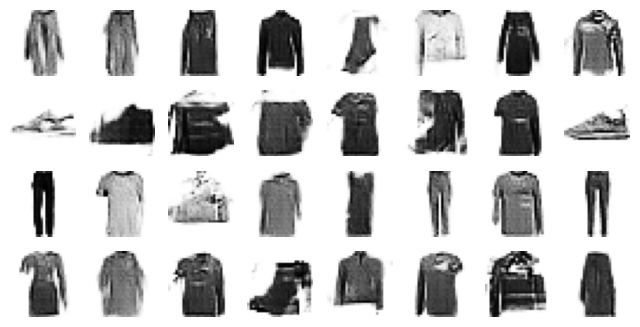

Epochs 8/10	FID: 138.6440183071266


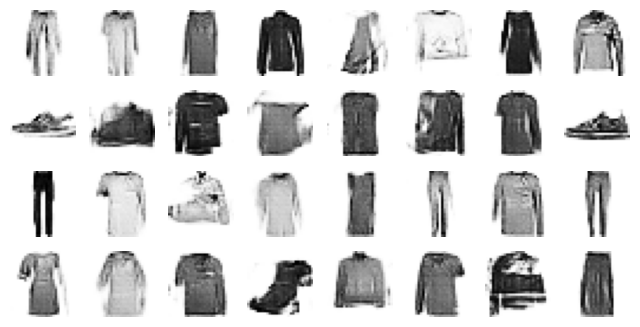

Epochs 9/10	FID: 140.8477977883852


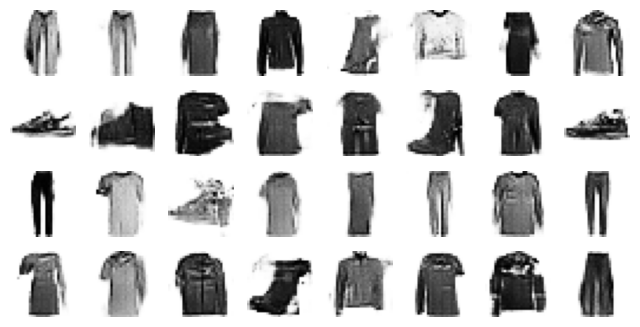

Epochs 10/10	FID: 139.68285886816136


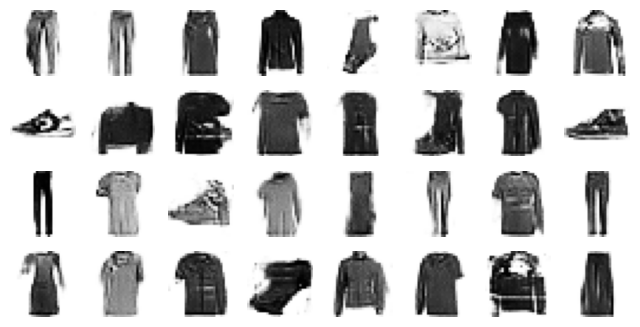

In [78]:
def train_dcgan_replay(dcgan, dataset, X_valid, batch_size,
                       feature_extractor, codings_size, n_epochs):
    generator, discriminator = dcgan.layers

    fids = []
    test_noise = tf.random.normal(shape=(batch_size, codings_size))
    replay_buffer = ReplayBuffer(10_000)
    real_features = feature_extractor.predict(X_valid[:batch_size], verbose=0)
    
    for epoch in range(n_epochs):
        print(f'Epochs {epoch + 1}/{n_epochs}', end='\t')
        
        for X_batch in dataset:
            replay_fakes = replay_buffer.sampling(batch_size // 2)
            if replay_fakes is None:
                noise = tf.random.normal(shape=(batch_size, codings_size))
                current_fakes = generator(noise)
                generated_images = current_fakes
            else:
                noise = tf.random.normal(shape=(batch_size - len(replay_fakes), codings_size))
                current_fakes = generator(noise)
                generated_images = tf.concat([current_fakes, replay_fakes], axis=0)
            replay_buffer.add(current_fakes)
            X_fake_and_real = tf.concat([generated_images, X_batch], axis=0)
            y1 = tf.constant([[0.]] * batch_size + [[1.]] * batch_size)
            discriminator.trainable = True
            discriminator.train_on_batch(X_fake_and_real, y1)

            for _ in range(2):
                noise = tf.random.normal(shape=(batch_size, codings_size))
                y2 = tf.constant([[1.]] * batch_size)
                discriminator.trainable = False
                dcgan.train_on_batch(noise, y2)

        fake_images = generator(test_noise, training=False)
        fake_features = feature_extractor.predict(fake_images, verbose=0)

        fid = calculate_fid(real_features, fake_features)
        fids.append(fid)
        print(f'FID: {fid}')
        
        plot_multiple_images(fake_images.numpy().copy(), 8)
        plt.show()
    
    return fids

tf.random.set_seed(42)
dcgan_replay = build_dcgan(codings_size)
fids = train_dcgan_replay(dcgan_replay, train_set, X_valid, batch_size=batch_size,
            feature_extractor=feature_extractor, codings_size=codings_size, n_epochs=10)

### ⑬

In [79]:
from PIL import Image

def display_generated_images(images):
    display_image = None
    if isinstance(images, np.ndarray):
        if images.ndim == 3:
            display_image = Image.fromarray(images)
        elif images.ndim == 4:
            concated_images = np.concatenate(list(images), axis=1)
            display_image = Image.fromarray(concated_images)
    elif isinstance(images, list):
        concated_images = np.concatenate(images, axis=1)
        display_image = Image.fromarray(concaten_images)

    if display_image is None:
        raise ValueError('Unsupported input format.')

    plt.figure(figsize=(10, 10))
    plt.axis('off')
    plt.imshow(display_image)
    plt.show()

In [80]:
import keras_hub

backbone = keras_hub.models.StableDiffusion3Backbone.from_preset(
    'stable_diffusion_3_medium', image_shape=(512, 512, 3), dtype='float16')
preprocessor = keras_hub.models.StableDiffusion3TextToImagePreprocessor.from_preset(
    'stable_diffusion_3_medium')
text_to_image = keras_hub.models.StableDiffusion3TextToImage(backbone, preprocessor)

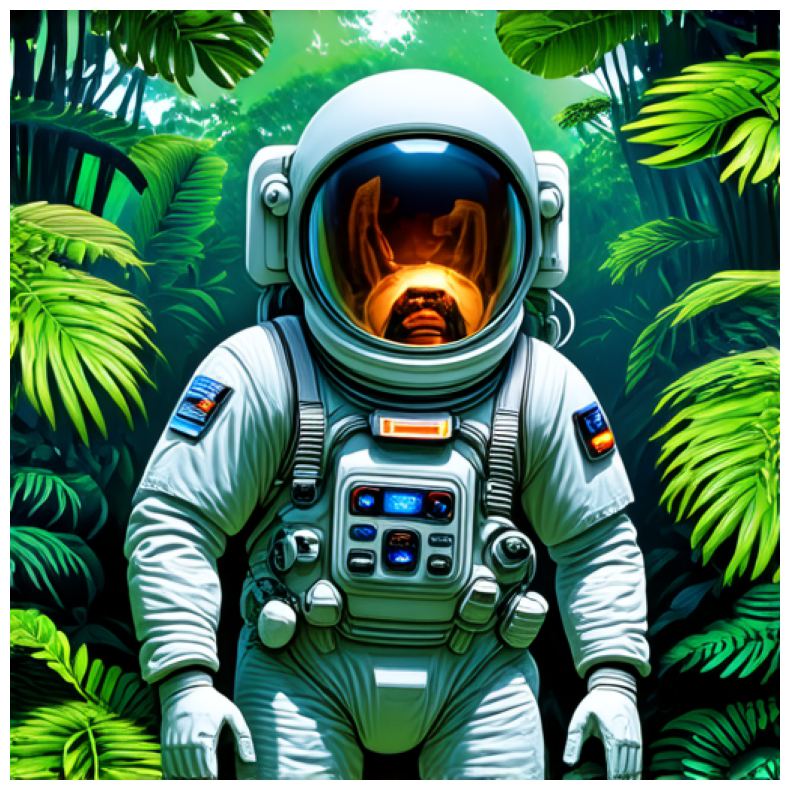

In [81]:
prompt = 'Astronaut in a jungle, cold color palette, muted colors, detailed, 8K'

generated_image = text_to_image.generate(prompt)
display_generated_images(generated_image)